In [3]:
from matplotlib.pyplot import subplots
import sklearn.model_selection as skm
from ISLP import load_data, confusion_table
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

import graphviz

# Make the simulation reproducible and create the image output folder.
np.random.seed(42)
Path('img').mkdir(exist_ok=True)

COLORS = [
    '#00B0F0',
    '#FF0000',
    '#B0F000'
]

# Importing dataset:

dataset = pd.read_stata(
    r"C:\Users\jonat\OneDrive\Desktop\Uni\Gerber et al 2008\GerberGreenLarimer_APSR_2008_social_pressure.dta",
    convert_categoricals=False
)

# Define treatment dummy variables and add them back into dataset:

dataset["treatment"] = dataset["treatment"].astype(int)
treatment_dummies = pd.get_dummies(dataset['treatment'], prefix='treatment', dtype=int)
dataset = pd.concat([dataset, treatment_dummies], axis=1)

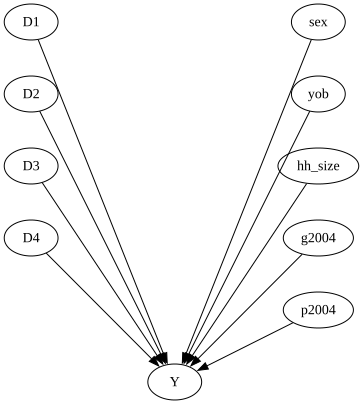

In [7]:
# DAG 1 - The Experiment

graph = graphviz.Digraph(format='png', engine='neato')

nodes = ['D1', 'D2', 'D3', 'D4',
         'sex', 'yob', 'hh_size', 'g2004', 'p2004', 'Y']

positions = ['0,4!', '0,3!', '0,2!', '0,1!',     # D nodes on left
             '4,4!', '4,3!', '4,2!', '4,1!',     # covariates on right
             '4,0!',                              # p2004 on lower right
             '2,-1!']                             # Y at bottom center

edges = [('D1', 'Y'), ('D2', 'Y'), ('D3', 'Y'), ('D4', 'Y'),
         ('sex', 'Y'), ('yob', 'Y'), ('hh_size', 'Y'),
         ('g2004', 'Y'), ('p2004', 'Y')]

[graph.node(n, pos=pos) for n, pos in zip(nodes, positions)]
graph.edges(edges)

graph.render('img/ch_05_markov_01')

graph

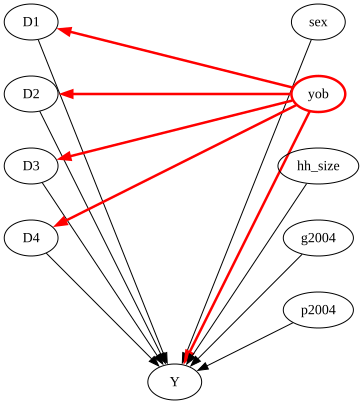

In [8]:
# DAG 2 - The Biased Sample

graph = graphviz.Digraph(format='png', engine='neato')

nodes = ['D1', 'D2', 'D3', 'D4',
         'sex', 'yob', 'hh_size', 'g2004', 'p2004', 'Y']

positions = ['0,4!', '0,3!', '0,2!', '0,1!',
             '4,4!', '4,3!', '4,2!', '4,1!',
             '4,0!', '2,-1!']

# Create nodes
[graph.node(n, pos=pos) for n, pos in zip(nodes, positions)]

# Original arrows to Y
edges = [('D1', 'Y'), ('D2', 'Y'), ('D3', 'Y'), ('D4', 'Y'),
         ('sex', 'Y'), ('hh_size', 'Y'),
         ('g2004', 'Y'), ('p2004', 'Y')]

graph.edges(edges)

# Highlight the backdoor path in red
graph.edge('yob', 'Y', color='red', penwidth='2.5')

for d in ['D1', 'D2', 'D3', 'D4']:
    graph.edge('yob', d, color='red', penwidth='2.5')

# Highlight yob node
graph.node('yob', pos='4,3!', color='red', penwidth='2.5')

graph.render('img/ch_05_markov_02')

graph